# Fashion Product Category Classification Using Logistic Regression

## Introduction

Fashion e-commerce platforms contain a large number of products with different
attributes such as product name, price, category, and subcategory.

In this project, a fashion product dataset is analyzed using Exploratory Data
Analysis (EDA) and Machine Learning techniques.

The main objective of this project is to clean the data, explore important
patterns, train a classification model, make predictions, and evaluate the
performance of the model.

The `category` column is used as the target variable to classify products into
different categories.

## Objectives

The main objectives of this project are:

1. Import and understand the dataset.
2. Perform data cleaning and preprocessing.
3. Perform Exploratory Data Analysis (EDA).
4. Visualize important patterns in the dataset.
5. Prepare the data for machine learning.
6. Split the data into training and testing sets.
7. Train classification models.
8. Make predictions on test data.
9. Evaluate the models using accuracy and other metrics.
10. Compare the model performance.

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import warnings
warnings.filterwarnings("ignore")

## Loading the Dataset

The dataset is loaded using the Pandas library.

In [2]:
df = pd.read_csv(r"C:\Users\Lavanya\Downloads\westside_combined.csv")

df.head()

,name,price,url,image_url,category,subcategory
0,Ascot Olive Relaxed-Fit Linen-Blend Shirt,"₹ 1,699.00",https://www.westside.com/collections/casual-sh...,https://cdn.shopify.com/s/files/1/0266/6276/45...,men,casual-shirts
1,Studiofit Black Text Design Cotton T-Shirt,₹ 499.00,https://www.westside.com/collections/t-shirts-...,https://cdn.shopify.com/s/files/1/0266/6276/45...,women,t-shirts
2,LUNA BLU Gold Rattan Weave Mary Jane Shoes,"₹ 1,499.00",https://www.westside.com/collections/footwear-...,https://cdn.shopify.com/s/files/1/0266/6276/45...,women,footwear
3,Wardrobe Navy High-Rise Accordion Skirt,"₹ 1,699.00",https://www.westside.com/collections/skirts-sh...,https://cdn.shopify.com/s/files/1/0266/6276/45...,women,skirts-shorts
4,Superstar White Ribbed Seam-Free Boy Shorts Brief,₹ 499.00,https://www.westside.com/collections/view-all-...,https://cdn.shopify.com/s/files/1/0266/6276/45...,women,lingerie-all


## Understanding the Dataset

The first few records are displayed to understand the structure and contents
of the dataset.

In [3]:
df.shape

(6915, 6)

In [4]:
df.columns

Index(['name', 'price', 'url', 'image_url', 'category', 'subcategory'], dtype='object')

## Dataset Description

The dataset contains information about fashion products.

Important columns include:

- `name` – Name of the fashion product
- `price` – Price of the product
- `url` – Product webpage URL
- `image_url` – Product image URL
- `category` – Main product category
- `subcategory` – Product subcategory

The `category` column is used as the target variable for classification.

## Checking Missing Values

Missing values can affect data analysis and machine learning.
Therefore, the dataset is checked for missing values.

In [6]:
df.isnull().sum()

name           0
price          0
url            0
image_url      0
category       0
subcategory    0
dtype: int64

## Checking Duplicate Values

Duplicate records can affect the analysis and model performance.
Therefore, duplicate records are identified.

In [7]:
df.duplicated().sum()

np.int64(1)

In [8]:
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (6914, 6)


## Data Cleaning

The price column contains currency symbols and commas.
Therefore, the price values are converted into numerical format.

In [9]:
df["price"] = (
    df["price"]
    .astype(str)
    .str.replace("₹", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
)

df["price"] = pd.to_numeric(df["price"], errors="coerce")

df.head()

,name,price,url,image_url,category,subcategory
0,Ascot Olive Relaxed-Fit Linen-Blend Shirt,1699.0,https://www.westside.com/collections/casual-sh...,https://cdn.shopify.com/s/files/1/0266/6276/45...,men,casual-shirts
1,Studiofit Black Text Design Cotton T-Shirt,499.0,https://www.westside.com/collections/t-shirts-...,https://cdn.shopify.com/s/files/1/0266/6276/45...,women,t-shirts
2,LUNA BLU Gold Rattan Weave Mary Jane Shoes,1499.0,https://www.westside.com/collections/footwear-...,https://cdn.shopify.com/s/files/1/0266/6276/45...,women,footwear
3,Wardrobe Navy High-Rise Accordion Skirt,1699.0,https://www.westside.com/collections/skirts-sh...,https://cdn.shopify.com/s/files/1/0266/6276/45...,women,skirts-shorts
4,Superstar White Ribbed Seam-Free Boy Shorts Brief,499.0,https://www.westside.com/collections/view-all-...,https://cdn.shopify.com/s/files/1/0266/6276/45...,women,lingerie-all


## Checking Data Types

After cleaning the price column, the data types of all columns are checked.

In [10]:
df.dtypes

name            object
price          float64
url             object
image_url       object
category        object
subcategory     object
dtype: object

# Exploratory Data Analysis

Exploratory Data Analysis is performed to understand the distribution of
fashion products and identify useful patterns in the dataset.

## Category Distribution

The number of products in each category is analyzed.

In [11]:
print(df["category"].value_counts())

category
women    4999
men      1915
Name: count, dtype: int64


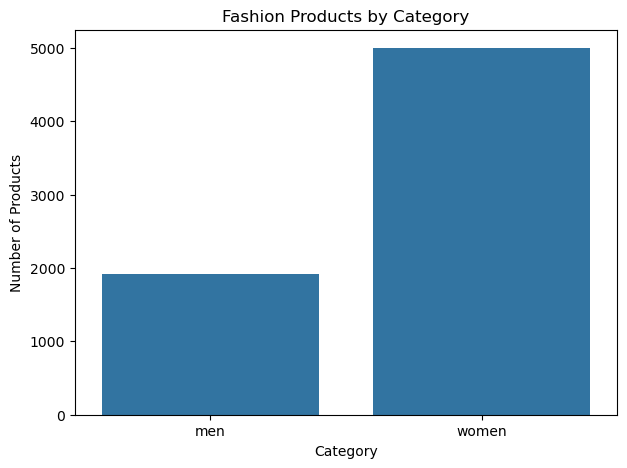

In [12]:
plt.figure(figsize=(7,5))

sns.countplot(data=df, x="category")

plt.title("Fashion Products by Category")
plt.xlabel("Category")
plt.ylabel("Number of Products")
plt.show()

## Price Distribution

The distribution of product prices is visualized using a histogram.

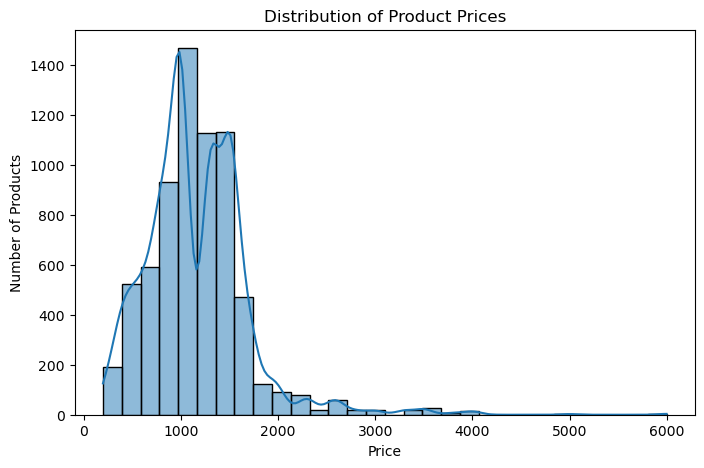

In [13]:
plt.figure(figsize=(8,5))

sns.histplot(df["price"], bins=30, kde=True)

plt.title("Distribution of Product Prices")
plt.xlabel("Price")
plt.ylabel("Number of Products")
plt.show()

## Average Price by Category

The average price of products in each category is calculated and visualized.

In [14]:
df.groupby("category")["price"].mean()

category
men      1193.386423
women    1146.219844
Name: price, dtype: float64

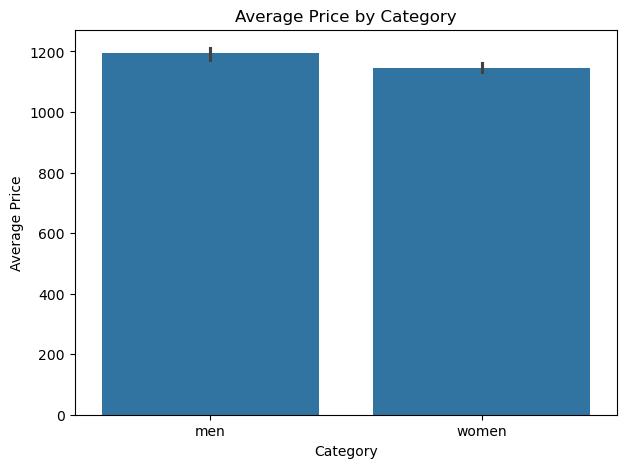

In [15]:
plt.figure(figsize=(7,5))

sns.barplot(data=df, x="category", y="price", estimator="mean")

plt.title("Average Price by Category")
plt.xlabel("Category")
plt.ylabel("Average Price")
plt.show()

## Product Subcategory Distribution

The most common product subcategories are analyzed.

In [16]:
df["subcategory"].value_counts().head(10)

subcategory
shirts-tops           707
co-ord-set            666
t-shirts              652
casual-shirts         520
footwear              460
kurtas                443
ethnic-co-ord-sets    357
lingerie-all          338
beauty                260
trousers-joggers      243
Name: count, dtype: int64

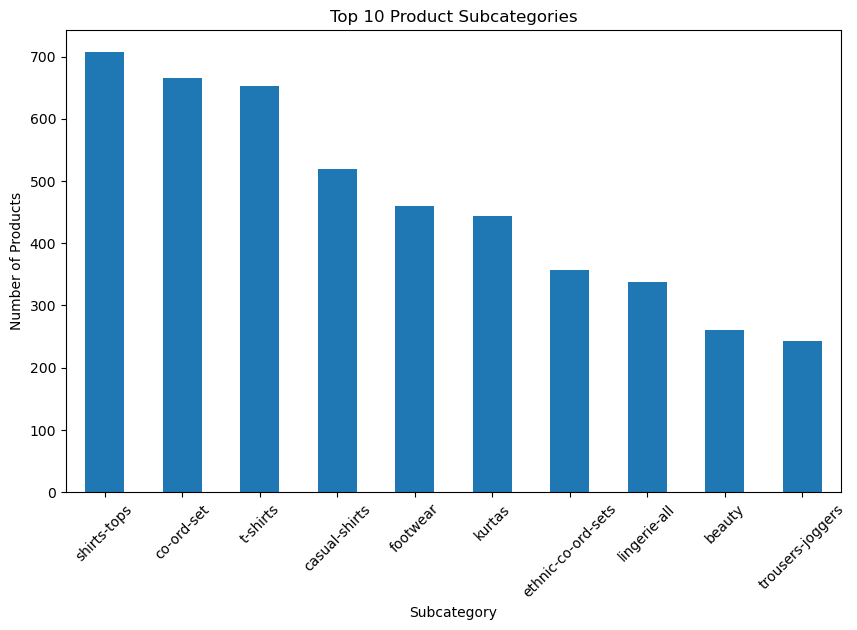

In [17]:
plt.figure(figsize=(10,6))

df["subcategory"].value_counts().head(10).plot(kind="bar")

plt.title("Top 10 Product Subcategories")
plt.xlabel("Subcategory")
plt.ylabel("Number of Products")
plt.xticks(rotation=45)

plt.show()

## Price Comparison by Category

A boxplot is used to compare the price distributions between product
categories.

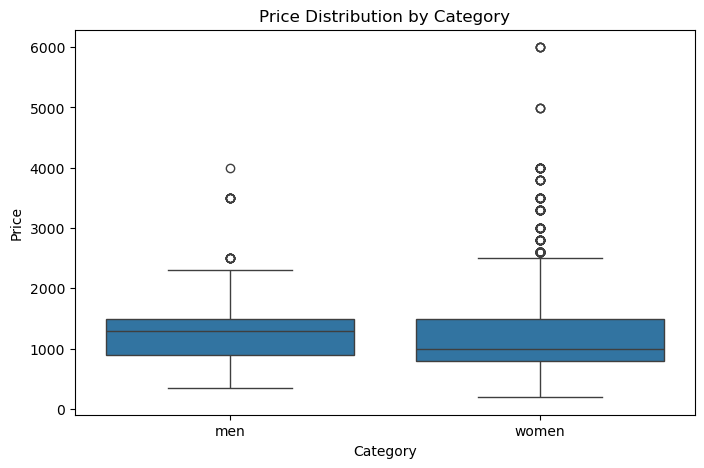

In [18]:
plt.figure(figsize=(8,5))

sns.boxplot(data=df, x="category", y="price")

plt.title("Price Distribution by Category")
plt.xlabel("Category")
plt.ylabel("Price")

plt.show()

# Machine Learning

The `category` column is selected as the target variable.

Since the product name contains useful textual information, TF-IDF is used
to convert product names into numerical features.

The model then learns the relationship between product names and their
categories.

In [19]:
X = df["name"]
y = df["category"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (6914,)
Target: (6914,)


## Splitting the Dataset

The dataset is divided into training and testing data.

80% of the data is used for training and 20% is used for testing.

In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 5531
Testing samples: 1383


## Text Feature Extraction Using TF-IDF

TF-IDF converts the product names into numerical features that can be
understood by the machine learning algorithm.

In [21]:
tfidf = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training feature shape:", X_train_tfidf.shape)
print("Testing feature shape:", X_test_tfidf.shape)

Training feature shape: (5531, 5113)
Testing feature shape: (1383, 5113)


## Training the Classification Model

Logistic Regression is used as the classification algorithm.

The model learns from the training data and predicts whether a product
belongs to the `men` or `women` category.

In [22]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train_tfidf, y_train)

print("Model training completed successfully.")

Model training completed successfully.


## Prediction

The trained model is used to predict the categories of the test data.

In [23]:
y_pred = model.predict(X_test_tfidf)

print("Predicted values:")
print(y_pred[:20])

Predicted values:
['women' 'women' 'women' 'men' 'women' 'women' 'men' 'men' 'men' 'women'
 'women' 'men' 'women' 'men' 'women' 'men' 'women' 'men' 'women' 'women']


## Model Accuracy

Accuracy is used to measure how many test samples were correctly classified.

In [24]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100, "%")

Model Accuracy: 0.9992769342010123
Accuracy Percentage: 99.92769342010122 %


## Classification Report

The classification report provides precision, recall, and F1-score for each
category.

In [25]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

         men       1.00      1.00      1.00       383
       women       1.00      1.00      1.00      1000

    accuracy                           1.00      1383
   macro avg       1.00      1.00      1.00      1383
weighted avg       1.00      1.00      1.00      1383



## Confusion Matrix

The confusion matrix shows the number of correctly and incorrectly
classified products for each category.

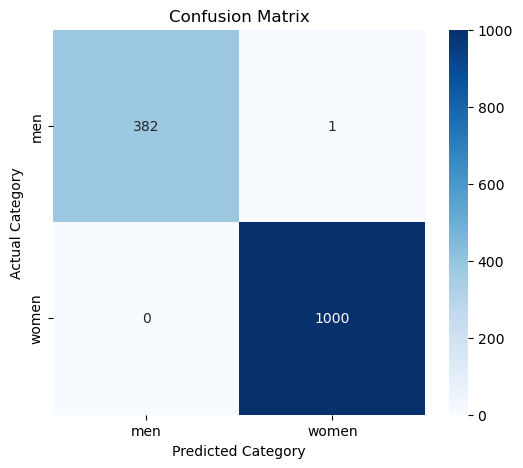

In [26]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")

plt.show()

## Testing the Model with a New Product

A new fashion product name is given to the trained model to demonstrate
prediction on unseen data.

In [27]:
new_product = ["Black Cotton Casual Shirt"]

new_product_tfidf = tfidf.transform(new_product)

prediction = model.predict(new_product_tfidf)

print("Product:", new_product[0])
print("Predicted Category:", prediction[0])

Product: Black Cotton Casual Shirt
Predicted Category: women


# Conclusion

In this project, a fashion product dataset was analyzed using Data Cleaning,
Exploratory Data Analysis, and Machine Learning techniques.

The dataset was cleaned by checking missing values, removing duplicate
records, and converting the price column into numerical format.

EDA was performed to understand product categories, prices, and
subcategories using different visualizations.

For classification, the product name was converted into numerical features
using TF-IDF. A Logistic Regression model was then trained using the training
data and evaluated using the testing data.

The model was used to predict the category of unseen fashion products.
Accuracy, precision, recall, F1-score, and a confusion matrix were used to
evaluate the classification performance.

Overall, this project demonstrates how data preprocessing, EDA, text feature
extraction, classification, prediction, and model evaluation can be combined
to build a complete machine learning workflow for fashion product
classification.